# Used Car Price Prediction
## Objective
The objective of this project is to build a machine learning regression model that predicts the price of a used car based on features such as brand, model, model year, mileage, fuel type, accident history, engine specifications, transmission type, and other available information.
The model will be trained using the provided training dataset and evaluated using validation data before generating predictions for the test dataset.
> Name:- Radhika Agarwal
> Roll No.:- 2026UCA1902



In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import mean_squared_error, mean_absolute_error

import warnings
warnings.filterwarnings("ignore")

## 1. Loading the Dataset

The training and test datasets are loaded using pandas. The training dataset contains the target variable `price`, while the test dataset does not contain price and will be used for final predictions.


In [2]:
train = pd.read_csv("/content/train (1).csv")
test = pd.read_csv("/content/test (2).csv")


FileNotFoundError: [Errno 2] No such file or directory: '/content/train (1).csv'

In [ ]:
train.head()

,id,brand,model,model_year,milage,fuel_type,ext_col,int_col,accident,clean_title,price,engine_displacement_l,engine_cylinders,transmission_type
0,1,Lexus,IS 300 Base,2018,"50,992 mi.",Gasoline,White,Gray,At least 1 accident or damage reported,Yes,"$28,000",3.5,6.0,Automatic
1,2,Chevrolet,Impala Base,2004,"64,500 mi.",Gasoline,Beige,Beige,None reported,Yes,"$5,900",3.4,6.0,Automatic
2,3,RAM,2500 SLT,2017,"86,000 mi.",Diesel,Gray,Gray,At least 1 accident or damage reported,Yes,"$41,000",6.7,6.0,Automatic
3,4,Mercedes-Benz,SL-Class SL 550,2013,"24,933 mi.",Gasoline,Silver,Red,At least 1 accident or damage reported,Yes,"$40,250",4.6,8.0,Other
4,5,Ford,Shelby GT350R Base,2018,"18,500 mi.",Gasoline,Blue,Black,At least 1 accident or damage reported,Yes,"$77,999",5.2,8.0,Manual


In [ ]:
test.head()

,id,brand,model,model_year,milage,fuel_type,ext_col,int_col,accident,clean_title,engine_displacement_l,engine_cylinders,transmission_type
0,3208,Buick,Envision Preferred,2021,"20,104 mi.",Gasoline,Burnished Bronze Metallic,Ebony,None reported,Yes,2.0,4.0,Automatic
1,3209,INFINITI,Q50 3.0T Premium,2016,"49,872 mi.",Gasoline,Gray,Black,At least 1 accident or damage reported,Yes,3.0,6.0,Automatic
2,3210,Cadillac,CTS Performance,2014,"34,988 mi.",Gasoline,Red,Black,None reported,Yes,3.6,6.0,Automatic
3,3211,Mercedes-Benz,SLC 300 Base,2019,"23,900 mi.",Gasoline,White,Black,None reported,Yes,2.0,4.0,Automatic
4,3212,Chevrolet,Malibu LTZ,2010,"55,900 mi.",Gasoline,Beige,Beige,None reported,Yes,3.6,6.0,Other


### Initial Observation

The training dataset contains the target variable `price`, whereas the test dataset contains the same vehicle related features without the target. The `price` and `mileage` columns require cleaning because they are stored as text.


In [ ]:
print("Train shape:", train.shape)
print("Test shape:", test.shape)

Train shape: (3207, 14)
Test shape: (802, 13)


The training dataset contains 3,207 rows and 14 columns, while the test dataset contains 802 rows and 13 columns. The extra column in the training data is the target variable `price`.

In [ ]:
train.columns

Index(['id', 'brand', 'model', 'model_year', 'milage', 'fuel_type', 'ext_col',
       'int_col', 'accident', 'clean_title', 'price', 'engine_displacement_l',
       'engine_cylinders', 'transmission_type'],
      dtype='object')

In [ ]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3207 entries, 0 to 3206
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     3207 non-null   int64  
 1   brand                  3207 non-null   object 
 2   model                  3207 non-null   object 
 3   model_year             3207 non-null   int64  
 4   milage                 3207 non-null   object 
 5   fuel_type              3074 non-null   object 
 6   ext_col                3207 non-null   object 
 7   int_col                3207 non-null   object 
 8   accident               3115 non-null   object 
 9   clean_title            2725 non-null   object 
 10  price                  3207 non-null   object 
 11  engine_displacement_l  3032 non-null   float64
 12  engine_cylinders       2856 non-null   float64
 13  transmission_type      3207 non-null   object 
dtypes: float64(2), int64(2), object(10)
memory usage: 350.9+

### Data Type Observation

Some numeric looking variables are stored as text. In particular, `mileage` contains commas and the `mi.` suffix, while `price` contains dollar signs and commas. These columns must be converted into numeric form before modelling.

In [ ]:
train.isnull()

,id,brand,model,model_year,milage,fuel_type,ext_col,int_col,accident,clean_title,price,engine_displacement_l,engine_cylinders,transmission_type
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3202,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3203,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3204,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3205,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [ ]:
train.isnull().sum()

,0
id,0
brand,0
model,0
model_year,0
milage,0
fuel_type,133
ext_col,0
int_col,0
accident,92
clean_title,482


### Missing Values

Several columns contain missing values, particularly `clean_title`, `engine_cylinders`, `engine_displacement_l`, `fuel_type`, and `accident`.

Missing categorical values will later be represented using an `Unknown` category, while numeric missing values will be handled using median imputation. This avoids assuming that a missing categorical value automatically means `No`.

In [ ]:
train_clean = train.copy()
test_clean = test.copy()

In [ ]:
if train_clean["price"].dtype == "object":
    train_clean["price"] = (
        train_clean["price"]
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False)
        .astype(float)
    )

In [ ]:
train_clean["price"].head()

,price
0,28000.0
1,5900.0
2,41000.0
3,40250.0
4,77999.0


In [ ]:
for df in [train_clean, test_clean]:
    if df["milage"].dtype == "object":
        df["milage"] = (
            df["milage"]
            .str.replace(" mi.", "", regex=False)
            .str.replace(",", "", regex=False)
            .astype(float)
        )

In [ ]:
print(train_clean[["milage", "price"]].head())
print(train_clean[["milage", "price"]].dtypes)

    milage    price
0  50992.0  28000.0
1  64500.0   5900.0
2  86000.0  41000.0
3  24933.0  40250.0
4  18500.0  77999.0
milage    float64
price     float64
dtype: object


In [ ]:
print(train_clean["price"].dtype)
print(train_clean["milage"].dtype)

float64
float64


In [ ]:
train_clean[["milage", "price"]].head()

,milage,price
0,50992.0,28000.0
1,64500.0,5900.0
2,86000.0,41000.0
3,24933.0,40250.0
4,18500.0,77999.0


The `milage` and `price` columns were converted from formatted strings into numeric variables by removing commas, currency symbols, and mileage suffixes.

In [ ]:
train_clean["price"].describe()

,price
count,3.207000e+03
mean,4.523930e+04
std,8.486586e+04
min,2.000000e+03
25%,1.700000e+04
50%,3.100000e+04
75%,4.990000e+04
max,2.954083e+06


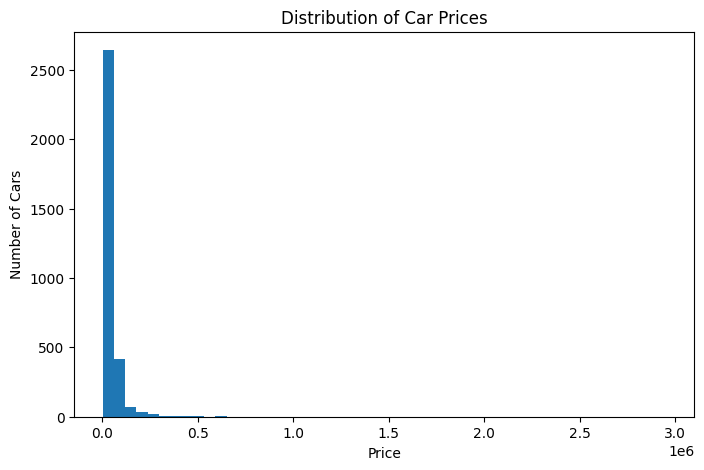

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(train_clean["price"], bins=50)
plt.xlabel("Price")
plt.ylabel("Number of Cars")
plt.title("Distribution of Car Prices")
plt.show()

### Price Distribution

The target variable is strongly right skewed. Most cars lie in a much lower price range, while a small number of vehicles have extremely high prices. These outliers are important because large prediction errors can strongly affect RMSE.

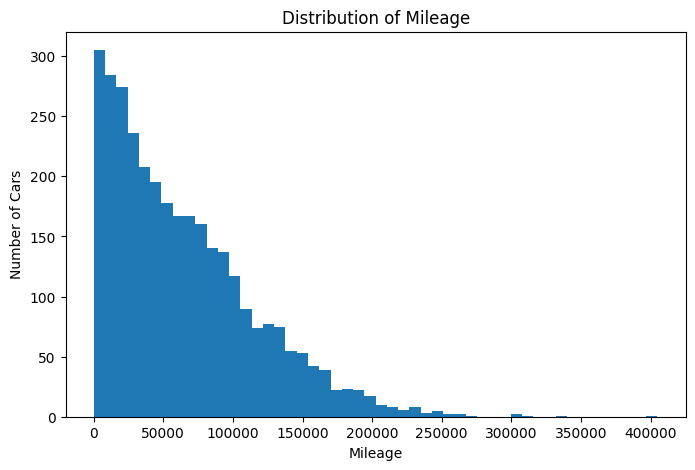

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(train_clean["milage"], bins=50)
plt.xlabel("Mileage")
plt.ylabel("Number of Cars")
plt.title("Distribution of Mileage")
plt.show()

In [ ]:
train_clean["milage"].describe()

,milage
count,3207.000000
mean,64697.689118
std,52184.748139
min,100.000000
25%,22490.000000
50%,53000.000000
75%,94826.500000
max,405000.000000


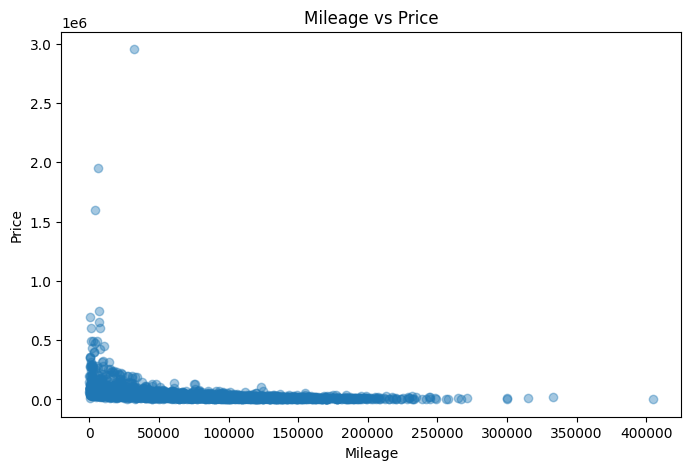

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(train_clean["milage"], train_clean["price"], alpha=0.4)
plt.xlabel("Mileage")
plt.ylabel("Price")
plt.title("Mileage vs Price")
plt.show()

The scatter plot is used to inspect whether higher mileage is associated with lower vehicle prices. The relationship is not perfectly linear because price is also influenced by other factors such as brand, model, age, and vehicle specifications.

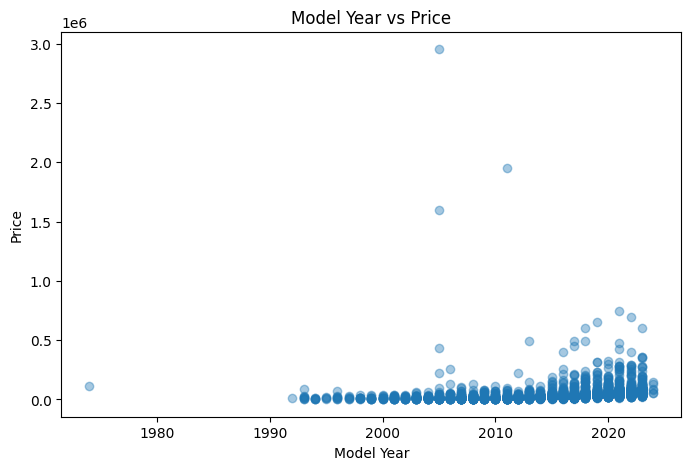

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(train_clean["model_year"], train_clean["price"], alpha=0.4)
plt.xlabel("Model Year")
plt.ylabel("Price")
plt.title("Model Year vs Price")
plt.show()

The plot helps examine whether newer vehicles tend to have higher prices. However, model year alone cannot explain price because rare or luxury older vehicles may still be expensive.

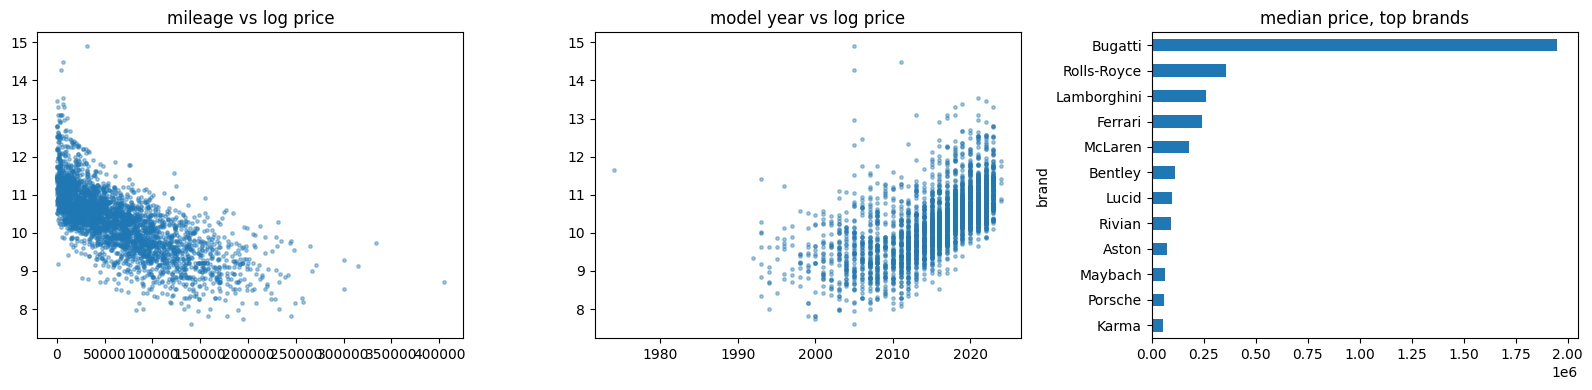

fuel_type
Gasoline          2650
Hybrid             159
NaN                133
E85 Flex Fuel      109
Diesel              90
–                   37
Plug-In Hybrid      27
not supported        2
Name: count, dtype: int64
clean_title
Yes    2725
NaN     482
Name: count, dtype: int64
unique brand/model: 57 1673


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].scatter(train_clean.milage, np.log1p(train_clean.price), s=6, alpha=.4); ax[0].set_title('mileage vs log price')
ax[1].scatter(train_clean.model_year, np.log1p(train_clean.price), s=6, alpha=.4); ax[1].set_title('model year vs log price')
train_clean.groupby('brand').price.median().sort_values().tail(12).plot.barh(ax=ax[2]); ax[2].set_title('median price, top brands')
plt.tight_layout(); plt.show()
print(train_clean.fuel_type.value_counts(dropna=False)); print(train_clean.clean_title.value_counts(dropna=False))
print('unique brand/model:', train_clean.brand.nunique(), train_clean.model.nunique())

In [ ]:
brand_price = (
    train_clean.groupby("brand")["price"]
    .median()
    .sort_values(ascending=False)
)

brand_price.head(15)

,price
brand,
Bugatti,1950995.0
Rolls-Royce,357425.0
Lamborghini,259000.0
Ferrari,243900.0
McLaren,179900.0
Bentley,113495.0
Lucid,99000.0
Rivian,92500.0
Aston,74997.5


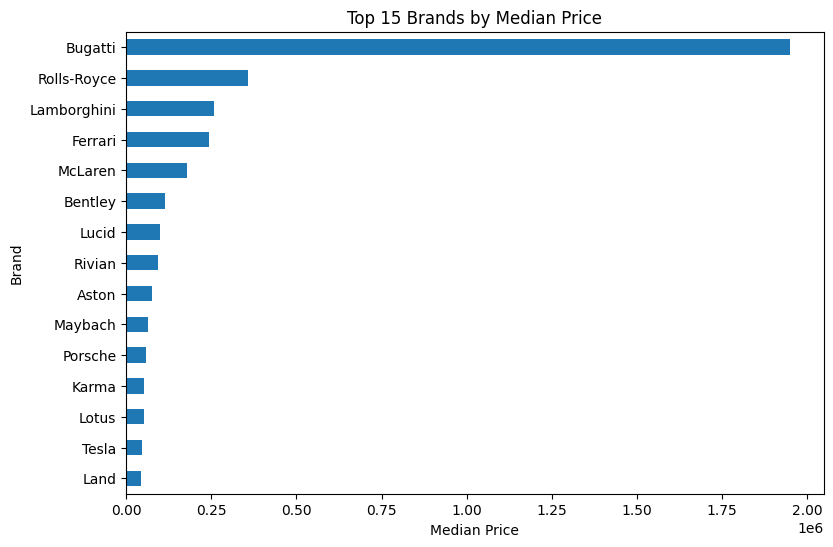

In [ ]:
brand_price.head(15).sort_values().plot(
    kind="barh",
    figsize=(9, 6)
)

plt.xlabel("Median Price")
plt.ylabel("Brand")
plt.title("Top 15 Brands by Median Price")
plt.show()

In [ ]:
reference_year = train_clean["model_year"].max()

for df in [train_clean, test_clean]:
    df["car_age"] = reference_year - df["model_year"]

In [ ]:
train_clean[["model_year", "car_age"]].head()

,model_year,car_age
0,2018,6
1,2004,20
2,2017,7
3,2013,11
4,2018,6


### Feature Engineering

A new feature called `car_age` was created from `model_year`. Car age may provide a more intuitive representation of vehicle depreciation than model year alone.

In [ ]:
for df in [train_clean, test_clean]:
    df["mileage_per_year"] = df["milage"] / (df["car_age"] + 1)

In [ ]:
X = train_clean.drop(columns=["price", "id"])
y = train_clean["price"]

In [ ]:
X.head()

,brand,model,model_year,milage,fuel_type,ext_col,int_col,accident,clean_title,engine_displacement_l,engine_cylinders,transmission_type,car_age,mileage_per_year
0,Lexus,IS 300 Base,2018,50992.0,Gasoline,White,Gray,At least 1 accident or damage reported,Yes,3.5,6.0,Automatic,6,7284.571429
1,Chevrolet,Impala Base,2004,64500.0,Gasoline,Beige,Beige,None reported,Yes,3.4,6.0,Automatic,20,3071.428571
2,RAM,2500 SLT,2017,86000.0,Diesel,Gray,Gray,At least 1 accident or damage reported,Yes,6.7,6.0,Automatic,7,10750.000000
3,Mercedes-Benz,SL-Class SL 550,2013,24933.0,Gasoline,Silver,Red,At least 1 accident or damage reported,Yes,4.6,8.0,Other,11,2077.750000
4,Ford,Shelby GT350R Base,2018,18500.0,Gasoline,Blue,Black,At least 1 accident or damage reported,Yes,5.2,8.0,Manual,6,2642.857143


In [ ]:
y.head()

,price
0,28000.0
1,5900.0
2,41000.0
3,40250.0
4,77999.0


In [ ]:
test_ids = test_clean["id"].copy()

In [ ]:
print(X.columns)

Index(['brand', 'model', 'model_year', 'milage', 'fuel_type', 'ext_col',
       'int_col', 'accident', 'clean_title', 'engine_displacement_l',
       'engine_cylinders', 'transmission_type', 'car_age', 'mileage_per_year'],
      dtype='object')


In [ ]:
test_ids=test_clean["id"].copy()
test_features = test_clean.drop(columns=["id"])

In [ ]:
print(test_ids.head())
print(test_features.columns)

0    3208
1    3209
2    3210
3    3211
4    3212
Name: id, dtype: int64
Index(['brand', 'model', 'model_year', 'milage', 'fuel_type', 'ext_col',
       'int_col', 'accident', 'clean_title', 'engine_displacement_l',
       'engine_cylinders', 'transmission_type', 'car_age', 'mileage_per_year'],
      dtype='object')


In [ ]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


In [ ]:
print(X_train.shape)
print(X_val.shape)

(2565, 14)
(642, 14)


In [ ]:
numeric_features = X_train.select_dtypes(include=["int64","float64"]).columns
categorical_features = X_train.select_dtypes(include=["object"]).columns

In [ ]:
print("Numeric columns:")
print(list(numeric_features))

print("\nCategorical columns:")
print(list(categorical_features))

Numeric columns:
['model_year', 'milage', 'engine_displacement_l', 'engine_cylinders', 'car_age', 'mileage_per_year']

Categorical columns:
['brand', 'model', 'fuel_type', 'ext_col', 'int_col', 'accident', 'clean_title', 'transmission_type']


In [ ]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

In [ ]:
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Unknown"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

missing > "Unknown"
BMW
Toyota
Ford

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

Numeric columns
> numeric preprocessing

Categorical columns
> categorical preprocessing

In [ ]:
linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

Raw car data
>
Preprocessing
>
Linear Regression

In [ ]:
linear_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['model_year', 'milage', 'engine_displacement_l', 'engine_cylinders',
       'car_age', 'mileage_per_year'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Unknown',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['brand', 'model', 'fuel_type', 'ext_col', 'int_col', 'accident',
       'clean_title', 'transmission_type'],
      dtype='object'))])),
                ('model', LinearRegression())])

In [ ]:
linear_predictions = linear_model.predict(X_val)

In [ ]:
linear_rmse = np.sqrt(
    mean_squared_error(y_val, linear_predictions)
)

linear_mae = mean_absolute_error(
    y_val,
    linear_predictions
)

print("Linear Regression RMSE:", linear_rmse)
print("Linear Regression MAE:", linear_mae)

Linear Regression RMSE: 118801.17005003149
Linear Regression MAE: 16962.58903305655


### Linear Regression Baseline

Linear Regression was used as the baseline model because it provides a simple reference point against which more flexible models can be compared.

The model was evaluated using RMSE and MAE on the validation set.

In [ ]:
random_forest = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=200,
                max_depth=15,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [ ]:
random_forest.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['model_year', 'milage', 'engine_displacement_l', 'engine_cylinders',
       'car_age', 'mileage_per_year'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Unknown',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['brand', 'model', 'fuel_type', 'ext_col', 'int_col', 'accident',
       'clean_title', 'transmission_type'],
      dtype='object'))])),
                ('model',
                 RandomForestRegressor(max_depth=15, n_estimators=200,
                                       n_jobs=-1, random_state=42))])

In [ ]:
rf_predictions = random_forest.predict(X_val)

In [ ]:
rf_rmse = np.sqrt(
    mean_squared_error(y_val, rf_predictions)
)

rf_mae = mean_absolute_error(
    y_val,
    rf_predictions
)

print("Random Forest RMSE:", rf_rmse)
print("Random Forest MAE:", rf_mae)

Random Forest RMSE: 118229.78153354714
Random Forest MAE: 15727.196795497646


### Random Forest

Random Forest was tested because car prices may depend on complex and nonlinear relationships between variables such as mileage, age, brand, engine characteristics, and accident history.

Its validation RMSE and MAE were compared with the Linear Regression baseline.

In [ ]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest"
    ],
    "RMSE": [
        linear_rmse,
        rf_rmse
    ],
    "MAE": [
        linear_mae,
        rf_mae
    ]
})

results

,Model,RMSE,MAE
0,Linear Regression,118801.170050,16962.589033
1,Random Forest,118229.781534,15727.196795


Random Forest achieved a lower validation RMSE than Linear Regression on this split, indicating that the nonlinear model captured useful relationships that the simple linear baseline did not capture as effectively.

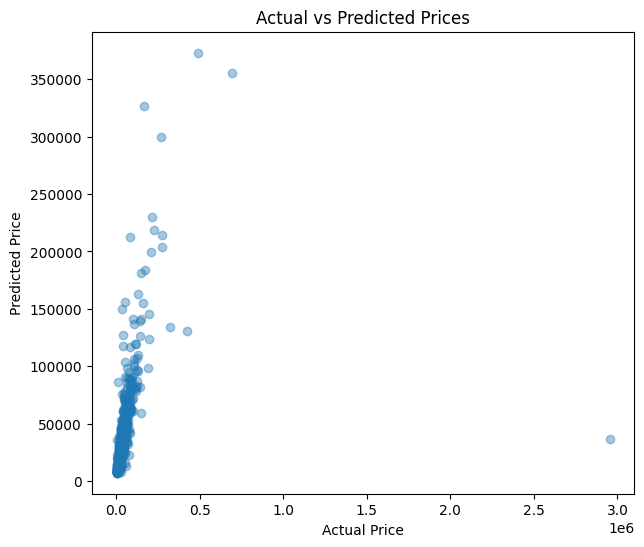

In [ ]:
plt.figure(figsize=(7, 6))
plt.scatter(y_val, rf_predictions, alpha=0.4)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Prices")

plt.show()

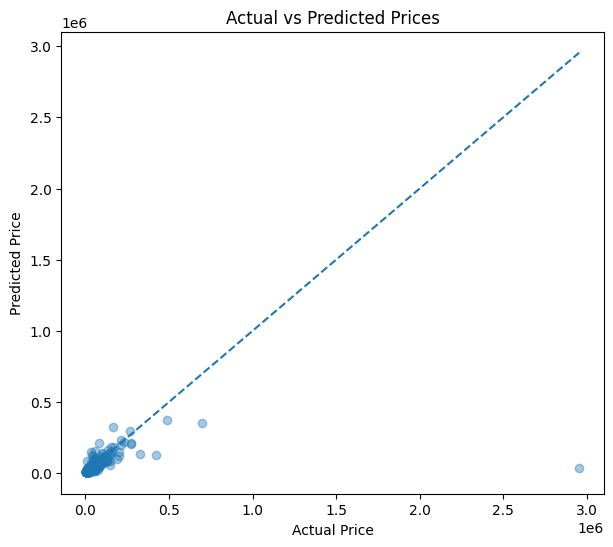

In [ ]:
min_value = min(y_val.min(), rf_predictions.min())
max_value = max(y_val.max(), rf_predictions.max())

plt.figure(figsize=(7, 6))
plt.scatter(y_val, rf_predictions, alpha=0.4)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Prices")
plt.show()

In [ ]:
from sklearn.tree import DecisionTreeRegressor

In [ ]:
decision_tree = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            DecisionTreeRegressor(
                max_depth=10,
                min_samples_leaf=5,
                random_state=42
            )
        )
    ]
)

In [ ]:
decision_tree.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['model_year', 'milage', 'engine_displacement_l', 'engine_cylinders',
       'car_age', 'mileage_per_year'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Unknown',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['brand', 'model', 'fuel_type', 'ext_col', 'int_col', 'accident',
       'clean_title', 'transmission_type'],
      dtype='object'))])),
                ('model',
                 DecisionTreeRegressor(max_depth=10, min_samples_leaf=5,
                                       random_state=42))])

In [ ]:
dt_predictions = decision_tree.predict(X_val)

In [ ]:
dt_rmse = np.sqrt(
    mean_squared_error(y_val, dt_predictions)
)

dt_mae = mean_absolute_error(
    y_val, dt_predictions
)

print("Decision Tree RMSE:", dt_rmse)
print("Decision Tree MAE:", dt_mae)

Decision Tree RMSE: 136839.4698067902
Decision Tree MAE: 24710.455347240564


In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

In [ ]:
gradient_boosting = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            GradientBoostingRegressor(
                n_estimators=200,
                learning_rate=0.05,
                max_depth=3,
                random_state=42
            )
        )
    ]
)

In [ ]:
gradient_boosting.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['model_year', 'milage', 'engine_displacement_l', 'engine_cylinders',
       'car_age', 'mileage_per_year'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Unknown',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['brand', 'model', 'fuel_type', 'ext_col', 'int_col', 'accident',
       'clean_title', 'transmission_type'],
      dtype='object'))])),
                ('model',
                 GradientBoostingRegressor(learning_rate=0.05, n_estimators=200,
                                           random_state=42))])

In [ ]:
gb_predictions = gradient_boosting.predict(X_val)

In [ ]:
gb_rmse = np.sqrt(
    mean_squared_error(y_val, gb_predictions)
)

gb_mae = mean_absolute_error(
    y_val, gb_predictions
)

print("Gradient Boosting RMSE:", gb_rmse)
print("Gradient Boosting MAE:", gb_mae)

Gradient Boosting RMSE: 119220.33100984267
Gradient Boosting MAE: 18197.253912952736


In [ ]:
!pip install xgboost -q

In [ ]:
from xgboost import XGBRegressor

In [ ]:
xgboost_model = Pipeline(
    steps=[
        ("preprocessor",
preprocessor),
        (
            "model",
            XGBRegressor(
                n_estimators=500,
learning_rate=0.03,
                max_depth=4,
                subsample=0.8,
colsample_bytree=0.8,
objective="reg:squarederror",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
 )

In [ ]:
xgboost_model.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['model_year', 'milage', 'engine_displacement_l', 'engine_cylinders',
       'car_age', 'mileage_per_year'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Unknown',...
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=0.03,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=4, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, multi_strategy=None,
                              n_estimators=500, n_jobs=-1,
                              num_parallel_tree=None, ...))])

In [ ]:
xgb_predictions = xgboost_model.predict(X_val)

In [ ]:
xgb_rmse = np.sqrt(
    mean_squared_error(y_val,
xgb_predictions)
)
xgb_mae = mean_absolute_error(
    y_val,xgb_predictions
)
print("XGBoost RMSE:", xgb_rmse)
print("XGBoost MAE:", xgb_mae)

XGBoost RMSE: 118188.52689981631
XGBoost MAE: 16380.31688312281


In [ ]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting",
        "XGBoost"
    ],
    "RMSE": [
        linear_rmse,
        dt_rmse,
        rf_rmse,
        gb_rmse,
        xgb_rmse

    ],
    "MAE": [
        linear_mae,
        dt_mae,
        rf_mae,
        gb_mae,
        xgb_mae
    ]
})

In [ ]:
results.sort_values("RMSE")

,Model,RMSE,MAE
4,XGBoost,118188.526900,16380.316883
2,Random Forest,118229.781534,15727.196795
0,Linear Regression,118801.170050,16962.589033
3,Gradient Boosting,119220.331010,18197.253913
1,Decision Tree,136839.469807,24710.455347


Lower RMSE = better validation result
>
Lower MAE = lower average prediction error

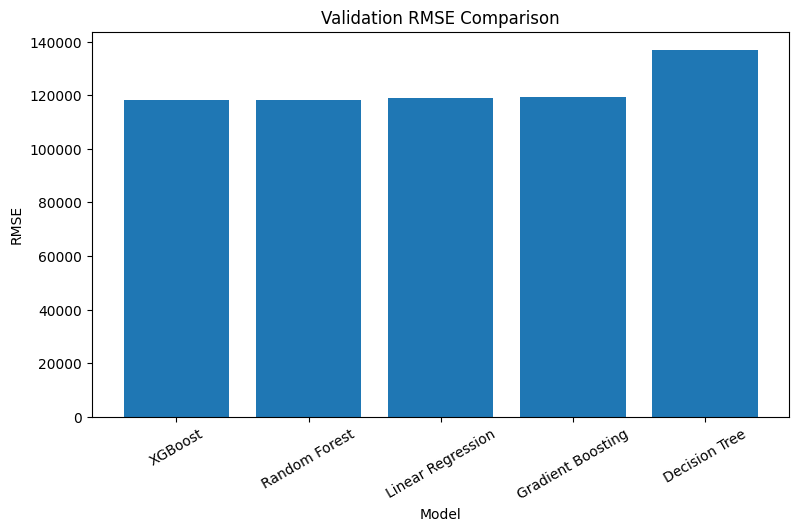

In [ ]:
results_sorted = results.sort_values("RMSE")

plt.figure(figsize=(9, 5))

plt.bar(
    results_sorted["Model"],
    results_sorted["RMSE"]
)

plt.xlabel("Model")
plt.ylabel("RMSE")
plt.title("Validation RMSE Comparison")

plt.xticks(rotation=30)

plt.show()

shorter bar = better

In [ ]:
best_row = results.loc[
    results["RMSE"].idxmin()
]

print(best_row)

Model         XGBoost
RMSE      118188.5269
MAE      16380.316883
Name: 4, dtype: object


In [ ]:
print("best model: XGBoost")
print("RMSE: 118188.5269")
print("MAE: 16380.3169")

best model: XGBoost
RMSE: 118188.5269
MAE: 16380.3169


In [ ]:
best_model = xgboost_model
best_model.fit(X, y)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['model_year', 'milage', 'engine_displacement_l', 'engine_cylinders',
       'car_age', 'mileage_per_year'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Unknown',...
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=0.03,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=4, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, multi_strategy=None,
                              n_estimators=500, n_jobs=-1,
                              num_parallel_tree=None, ...))])

In [ ]:
X_train
y_train

,price
460,33500.0
43,29999.0
87,28000.0
2437,32500.0
990,43550.0
...,...
1095,23000.0
1130,39979.0
1294,66000.0
860,53800.0


In [ ]:
test_predictions = best_model.predict(
    test_features
)

In [ ]:
print(len(test_predictions))

802


In [ ]:
submission = pd.DataFrame({
    "id": test_ids,
    "price": test_predictions
})

In [ ]:
submission.head()
submission.shape

(802, 2)

In [ ]:
submission.to_csv(
    "submission.csv",
    index=False
)

## Conclusion

In this project, the used-car dataset was explored and cleaned before training machine learning models.

The price and mileage variables were prepared for modelling, missing values were handled using preprocessing pipelines, categorical features were encoded, and additional features such as car age were created.

Five regression models were evaluated:

1. Linear Regression
2. Decision Tree
3. Random Forest
4. Gradient Boosting
5. XGBoost

The models were compared using RMSE and MAE on the same validation dataset.

The model with the lowest validation RMSE was selected for final prediction. The selected model was retrained using the complete training dataset and used to generate predictions for the test dataset.

The predictions were saved in submission.csv using the required id and price columns.